<a href="https://colab.research.google.com/github/klyoo/sds510/blob/main/SDS_510_Module_3_Essentials.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Module 3 Essentails: Phoenix Crime and Temperature analysis**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

crime = pd.read_csv(
    "crimestat (1).csv",
    engine="python",
    on_bad_lines="skip"
)

weather = pd.read_csv(
    "open-meteo-33.43N112.03W333m (1).csv",
    skiprows=2
)

In [2]:
crime.head()

,INC NUMBER,OCCURRED ON,OCCURRED TO,UCR CRIME CATEGORY,100 BLOCK ADDR,ZIP,PREMISE TYPE
0,201600000052855,11/01/2015 00:00,01/09/2016 00:00,MOTOR VEHICLE THEFT,N 43RD AVE & W CACTUS RD,85029.0,SINGLE FAMILY HOUSE
1,201600000594484,11/01/2015 00:00,NaN,RAPE,13XX E ALMERIA RD,85006.0,SINGLE FAMILY HOUSE
2,201500002102327,11/01/2015 00:00,11/01/2015 09:00,LARCENY-THEFT,51XX N 15TH ST,85014.0,APARTMENT
3,201500002101405,11/01/2015 00:00,11/01/2015 05:00,MOTOR VEHICLE THEFT,102XX W MEDLOCK AVE,85307.0,SINGLE FAMILY HOUSE
4,201500002102668,11/01/2015 00:00,11/01/2015 11:50,MOTOR VEHICLE THEFT,69XX W WOOD ST,85043.0,SINGLE FAMILY HOUSE


In [3]:
weather.head()

,time,temperature_2m_mean (°C)
0,2015-11-01,19.0
1,2015-11-02,19.2
2,2015-11-03,18.0
3,2015-11-04,15.0
4,2015-11-05,12.8


**Data description**

I used two datsets for this project.

The first dataset is crime stats in Phoenix. This dataset contains crime records, crime categories, dates, and location.

The second dataset is daily temperature in Phoenix from November 2015 to November 2017. This dataset contains date and avaerage daily temperature.

In [4]:
crime["DATE"] = pd.to_datetime(
    crime["OCCURRED ON"],
    errors="coerce"
).dt.normalize()

crime[["OCCURRED ON", "DATE"]].head()

,OCCURRED ON,DATE
0,11/01/2015 00:00,2015-11-01
1,11/01/2015 00:00,2015-11-01
2,11/01/2015 00:00,2015-11-01
3,11/01/2015 00:00,2015-11-01
4,11/01/2015 00:00,2015-11-01


In [5]:
weather = weather.rename(columns={
    "time": "DATE",
    "temperature_2m_mean (°C)": "TEMPERATURE"
})

weather["DATE"] = pd.to_datetime(weather["DATE"])

weather.head()

,DATE,TEMPERATURE
0,2015-11-01,19.0
1,2015-11-02,19.2
2,2015-11-03,18.0
3,2015-11-04,15.0
4,2015-11-05,12.8


In [6]:
daily_crime = crime.groupby("DATE").size()

daily_crime.head()

,0
DATE,
2015-11-01,161
2015-11-02,158
2015-11-03,177
2015-11-04,165
2015-11-05,143


In [7]:
daily_crime = daily_crime.reset_index(name="CRIME COUNT")

daily_crime.head()

,DATE,CRIME COUNT
0,2015-11-01,161
1,2015-11-02,158
2,2015-11-03,177
3,2015-11-04,165
4,2015-11-05,143


In [8]:
merged = pd.merge(
    daily_crime,
    weather,
    on="DATE",
    how="inner"
)

merged.head()

,DATE,CRIME COUNT,TEMPERATURE
0,2015-11-01,161,19.0
1,2015-11-02,158,19.2
2,2015-11-03,177,18.0
3,2015-11-04,165,15.0
4,2015-11-05,143,12.8


**Data Preparation and Merging**

I first started to prepare the datasets for the analysis.

I converted the dates into same format for each dataset.

Then, I used groupby() and size() to calculate number of crimes for each date.

After that, I used merge() to combine two datasets that contains daily crime counts and daily average temperature.

This merged dataset contains data, daily crime count, and daily average temperature.

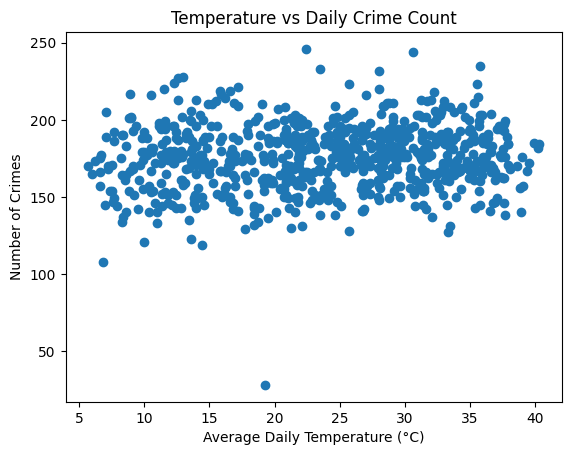

In [14]:
plt.scatter(merged["TEMPERATURE"], merged["CRIME COUNT"])

plt.xlabel("Average Daily Temperature (°C)")
plt.ylabel("Number of Crimes")
plt.title("Temperature vs Daily Crime Count")
plt.show()

**Analysis 1: Temperature vs. Daily Crime Count Scatter Plot**

For the first analysis, I created scatter plot to compare daily average temperature and daily crime count.

Each point on the scatter plot represent one day.

According to the scatter plot, it does not show clear relationship between temperature and daily crime count.

In [10]:
merged["TEMP GROUP"] = pd.cut(
    merged["TEMPERATURE"],
    bins=[0, 15, 25, 50],
    labels=["Cold", "Mild", "Hot"]
)

merged.head()

,DATE,CRIME COUNT,TEMPERATURE,TEMP GROUP
0,2015-11-01,161,19.0,Mild
1,2015-11-02,158,19.2,Mild
2,2015-11-03,177,18.0,Mild
3,2015-11-04,165,15.0,Cold
4,2015-11-05,143,12.8,Cold


In [11]:
crime_by_temp = merged.groupby(
    "TEMP GROUP", observed=True
)["CRIME COUNT"].mean()

crime_by_temp

,CRIME COUNT
TEMP GROUP,
Cold,173.271084
Mild,173.574561
Hot,178.028249


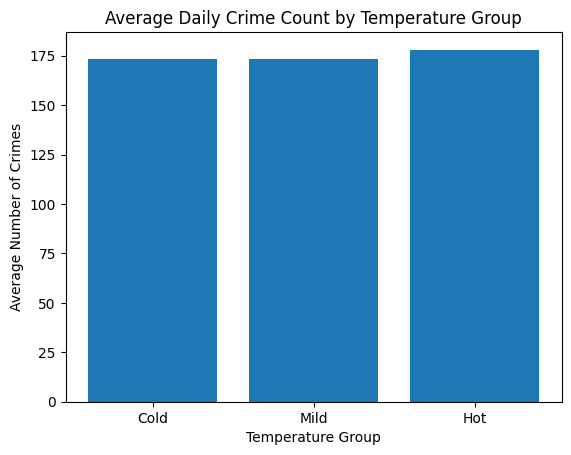

In [15]:
plt.bar(crime_by_temp.index, crime_by_temp.values)

plt.title("Average Daily Crime Count by Temperature Group")
plt.xlabel("Temperature Group")
plt.ylabel("Average Number of Crimes")
plt.show()

**Analysis 2: Average Daily Crime vs. Temperature group Bar Chart**

For the second analysis, I divided temperature into three groups: Cold (15°C or below), Mild (15°C - 25°C), and Hot (Above 25°C).

Then, I used groupby() and mean() to calculate the average daily crime counts for each temperature group.

According to the bar chart, Hot temperature group showed highest average daily crime count, and Cold temperature group showed lowest average daily crime count.

However, the differences between these three groups were very small, which suggests that temperature alone may not explain the differnece in crime counts.

In [16]:
merged.to_csv("Phoenix_Crime_Weather.csv", index=False)

**Exporting the Results in CSV**

I used to_csv() to save the merged dataset as 'Phoenix_Crime_Weather.csv'.

This csv file contains dates, daily crime counts, daily average temperature, and temperature groups.